Dataset loaded from the internet.
Shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1   

Outcome distribution:
 Outcome
0    500
1    268
Name: count, dtype: int64 

=== Cross-Validation Results (mean) ===
              Model  accuracy  precision  recall     f1  roc_auc
          SVM (RBF)    0.7605     0.6372  0.7617 0.6902   0.8371
Logi

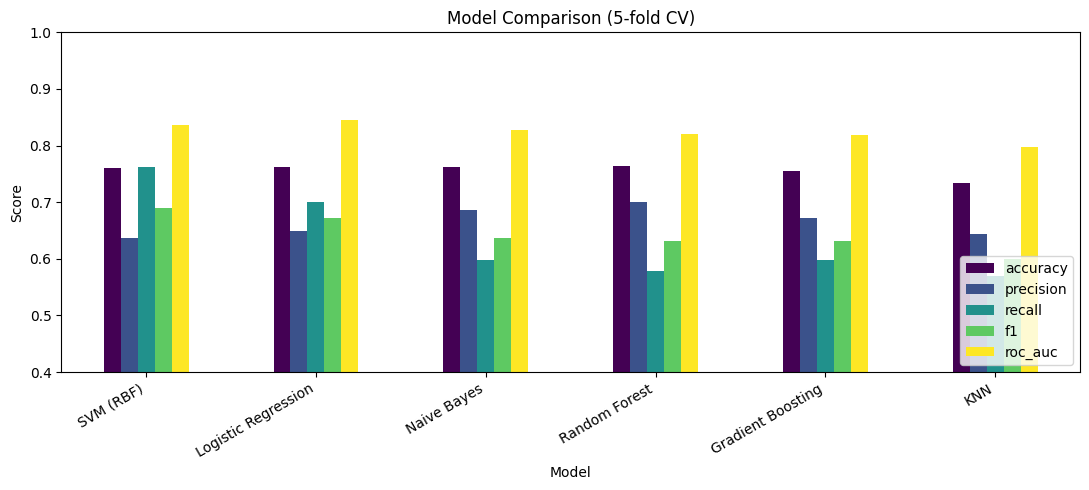


Best parameters: {'clf__max_depth': 5, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 100}
Best CV F1-Score: 0.7048

=== Test Set Results ===
                 Model  Accuracy  Precision  Recall     F1  ROC-AUC
Naive Bayes (baseline)    0.7013     0.5667  0.6296 0.5965   0.7646
   Tuned Random Forest    0.7273     0.5909  0.7222 0.6500   0.8180

Classification Report (Tuned Random Forest):
              precision    recall  f1-score   support

 No Diabetes       0.83      0.73      0.78       100
    Diabetes       0.59      0.72      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.71       154
weighted avg       0.75      0.73      0.73       154



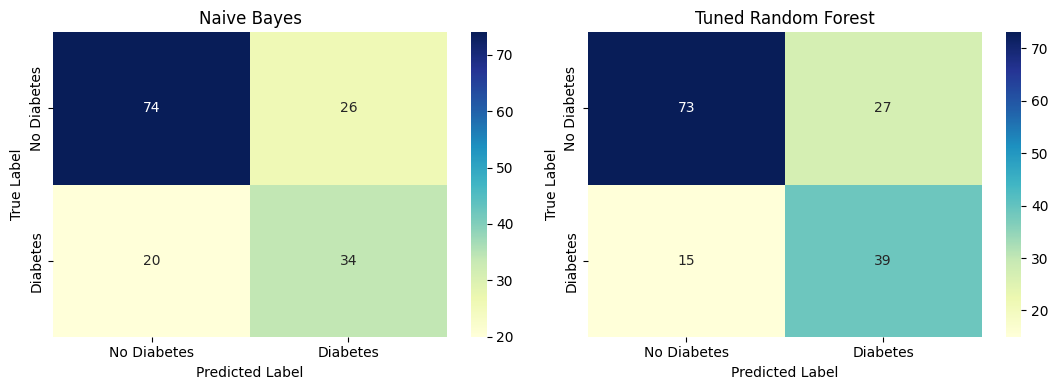

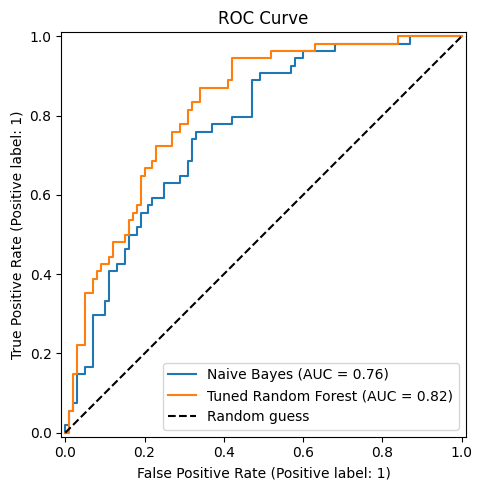

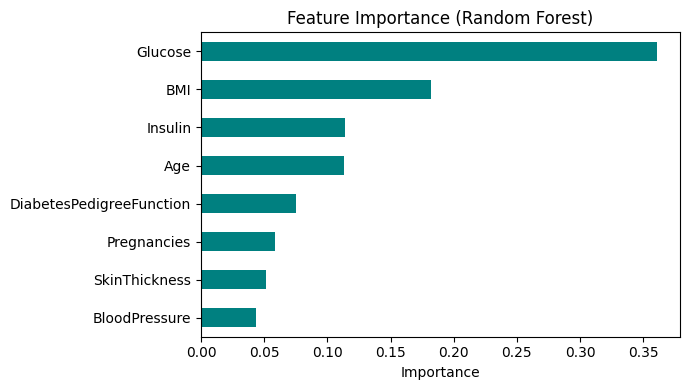


Feature importance (highest to lowest):
Glucose                     0.3611
BMI                         0.1823
Insulin                     0.1143
Age                         0.1134
DiabetesPedigreeFunction    0.0751
Pregnancies                 0.0588
SkinThickness               0.0514
BloodPressure               0.0435
dtype: float64


In [3]:
# ========== 1. Libraries ==========
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay)

# ========== 2. Load data (from the internet; falls back to upload) ==========
cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
        'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

try:
    df = pd.read_csv(url, header=None, names=cols)
    print("Dataset loaded from the internet.")
except Exception as e:
    print("Could not load from the link, please upload the file. Reason:", e)
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])

print("Shape:", df.shape)  # should be (768, 9)
print(df.head(), "\n")
print("Outcome distribution:\n", df['Outcome'].value_counts(), "\n")

# ========== 3. Preprocessing ==========
# In these columns, a value of 0 is actually a missing value
invalid_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[invalid_zero_cols] = df[invalid_zero_cols].replace(0, np.nan)

X = df.drop('Outcome', axis=1)
y = df['Outcome']

# stratify=y keeps the same class ratio in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Imputer and scaler are inside the Pipeline to avoid data leakage
def make_pipe(model, scale=True):
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scaler', StandardScaler()))
    steps.append(('clf', model))
    return Pipeline(steps)

# ========== 4. Compare multiple models (5-fold cross-validation) ==========
models = {
    'Naive Bayes':         make_pipe(GaussianNB()),
    'Logistic Regression': make_pipe(LogisticRegression(max_iter=1000, class_weight='balanced')),
    'SVM (RBF)':           make_pipe(SVC(class_weight='balanced', probability=True, random_state=42)),
    'KNN':                 make_pipe(KNeighborsClassifier(n_neighbors=7)),
    'Random Forest':       make_pipe(RandomForestClassifier(class_weight='balanced', random_state=42), scale=False),
    'Gradient Boosting':   make_pipe(GradientBoostingClassifier(random_state=42), scale=False),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

rows = []
for name, pipe in models.items():
    cv = cross_validate(pipe, X_train, y_train, cv=skf, scoring=scoring)
    row = {'Model': name}
    for m in scoring:
        row[m] = cv[f'test_{m}'].mean()
    rows.append(row)

cv_df = pd.DataFrame(rows).sort_values('f1', ascending=False).reset_index(drop=True)
print("=== Cross-Validation Results (mean) ===")
print(cv_df.round(4).to_string(index=False))

cv_df.set_index('Model')[scoring].plot(kind='bar', figsize=(11, 5), colormap='viridis')
plt.title('Model Comparison (5-fold CV)')
plt.ylabel('Score')
plt.ylim(0.4, 1.0)
plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# ========== 5. Hyperparameter tuning (Random Forest) ==========
rf_pipe = make_pipe(RandomForestClassifier(class_weight='balanced', random_state=42), scale=False)
param_grid = {
    'clf__n_estimators': [100, 300],
    'clf__max_depth': [None, 5, 10],
    'clf__min_samples_leaf': [1, 3, 5],
}
grid = GridSearchCV(rf_pipe, param_grid, cv=skf, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)

print("\nBest parameters:", grid.best_params_)
print(f"Best CV F1-Score: {grid.best_score_:.4f}")
best_model = grid.best_estimator_

# ========== 6. Final evaluation on the test set ==========
nb_model = make_pipe(GaussianNB()).fit(X_train, y_train)

def evaluate(model, name):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {'Model': name,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, proba)}

final_df = pd.DataFrame([evaluate(nb_model, 'Naive Bayes (baseline)'),
                         evaluate(best_model, 'Tuned Random Forest')])
print("\n=== Test Set Results ===")
print(final_df.round(4).to_string(index=False))

print("\nClassification Report (Tuned Random Forest):")
print(classification_report(y_test, best_model.predict(X_test),
                            target_names=['No Diabetes', 'Diabetes']))

# Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (m, title) in zip(axes, [(nb_model, 'Naive Bayes'), (best_model, 'Tuned Random Forest')]):
    cm = confusion_matrix(y_test, m.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', ax=ax,
                xticklabels=['No Diabetes', 'Diabetes'],
                yticklabels=['No Diabetes', 'Diabetes'])
    ax.set_title(title)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
plt.tight_layout()
plt.show()

# ROC curve
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(nb_model, X_test, y_test, name='Naive Bayes', ax=ax)
RocCurveDisplay.from_estimator(best_model, X_test, y_test, name='Tuned Random Forest', ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_title('ROC Curve')
ax.legend()
plt.tight_layout()
plt.show()

# ========== 7. Feature importance ==========
importances = pd.Series(best_model.named_steps['clf'].feature_importances_,
                        index=X.columns).sort_values()
plt.figure(figsize=(7, 4))
importances.plot(kind='barh', color='teal')
plt.title('Feature Importance (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print("\nFeature importance (highest to lowest):")
print(importances.sort_values(ascending=False).round(4))